# F02_03 — Suavizamiento exponencial y ETS

## Propósito de la sesión

En Semana 2 establecimos cómo evaluar mean, naive y drift fuera de muestra. Ahora buscamos actualizar gradualmente el nivel y la tendencia.

> **¿Cuándo un modelo de suavizamiento exponencial realmente aporta valor frente a un benchmark simple?**

Al finalizar, el estudiante podrá seleccionar, ajustar, evaluar e interpretar modelos de suavizamiento exponencial, distinguiendo entre nivel, tendencia y error, y comparando su desempeño contra benchmarks simples mediante evaluación fuera de muestra.

### Cómo trabajar este notebook

- 📘 **Concepto**
- 🌍 **Contexto**
- 💻 **Entendamos el código**
- 🧠 **Predice**
- ▶ **Ejecuta**
- 🔎 **Interpreta**
- ▶ **Ver respuesta razonada**
- 🛠️ **Modifica**

Se ofrece menos ayuda de sintaxis que en Semana 2: lea los objetos y justifique antes de modificar.

## 1. Preparación del notebook

Este notebook es autocontenido: no necesita ejecutar otras sesiones ni descargar datos.

In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
from statsforecast.models import AutoETS

candidatos = []

for base in [Path.cwd(), *Path.cwd().parents]:
    candidatos.extend([
        base / "data/fpppy",
        base / "content/data/fpppy",
    ])

DATA_DIR = next(
    (p for p in candidatos if (p / "www_usage.csv").exists()),
    None
)

assert DATA_DIR is not None, (
    "No se encontró www_usage.csv en data/fpppy "
    "ni en content/data/fpppy."
)
sns.set_style("whitegrid")

## 2. De los benchmarks a un nivel que se actualiza

### 📘 Concepto

Mean conserva el promedio histórico; naive solo el último dato; drift extrapola el cambio entre los extremos de train. Necesitamos candidatos que adapten gradualmente el nivel y la tendencia a la información reciente. Mayor flexibilidad no garantiza mejores pronósticos.

### 🌍 Contexto — uso de Internet

`www_usage.csv`, de la colección local FPPPy, contiene 100 observaciones del número de usuarios conectados a un servidor, medidas cada **minuto**. $Y_t$ es la variable cuantitativa y $y_t$ su realización. Sus cambios de nivel y tendencia local permiten contrastar métodos sin imponer estacionalidad. Es un ejemplo distinto de los casos semanales del proyecto.

Conservamos la lógica de Semana 2: últimas 12 observaciones como test, un único origen, ajuste solo con train. Aquí $h=12$ significa 12 minutos.

### 🧠 Predice

¿La pendiente global de drift siempre representa la dirección más reciente? ¿Qué ocurriría si prolongamos indefinidamente esa dirección?

Train: 88; test: 12; horizonte: 12 minutos


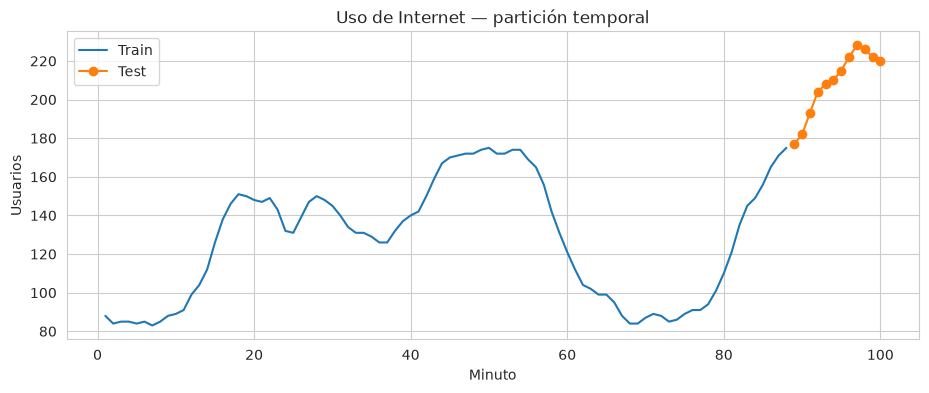

In [24]:
serie = pd.read_csv(DATA_DIR / "www_usage.csv").sort_values("ds").reset_index(drop=True)
h = 12
train = serie.iloc[:-h].copy()
test = serie.iloc[-h:].copy()
y_train = train["y"].to_numpy(dtype=float)
y_test = test["y"].to_numpy(dtype=float)
assert train["ds"].max() < test["ds"].min()
print(f"Train: {len(train)}; test: {len(test)}; horizonte: {h} minutos")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train["ds"], y_train, label="Train")
ax.plot(test["ds"], y_test, marker="o", label="Test")
ax.set(title="Uso de Internet — partición temporal", xlabel="Minuto", ylabel="Usuarios")
ax.legend()
plt.show()

### 🔎 Interpreta

Describa los cambios de dirección en train. Explique por qué una única pendiente podría ser insuficiente.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

La dirección local puede cambiar. Una pendiente entre los extremos no resume todos los tramos; prolongar la última pendiente durante mucho tiempo también puede ser poco razonable. El test evalúa y no se utiliza para estimar parámetros.

</details>

## 3. SES: un nivel con memoria

### 📘 Concepto

Simple exponential smoothing (SES) es candidato cuando no necesitamos tendencia persistente ni estacionalidad explícita:

$$
\ell_t=\alpha y_t+(1-\alpha)\ell_{t-1},\qquad 0\leq\alpha\leq1
$$

$$
\hat{y}_{T+k|T}=\ell_T,\qquad k=1,\ldots,h
$$

$\ell_t$ estima el nivel, $\alpha$ controla la actualización y $\ell_0$ es el nivel inicial. La sustitución recursiva da pesos geométricamente decrecientes a observaciones antiguas.

- $\alpha$ cercano a 0: mucha memoria, nivel suave, reacción lenta.
- $\alpha$ cercano a 1: mucha reacción al último dato y poca suavización; con 1 coincide con naive.

SES genera pronósticos horizontales, aunque su nivel cambia dentro de train. $\alpha$ no es una probabilidad de acierto.

### 🧠 Predice

Entre 0.1, 0.5 y 0.9, ¿qué alpha seguirá más las oscilaciones y cuál responderá más tarde?

### 💻 Entendamos el código

Fijamos el mismo nivel inicial para aislar el efecto de alpha. `niveles[1:]` son niveles actualizados después de observar cada dato: no son predicciones previas a observarlo.

### ▶ Ejecuta

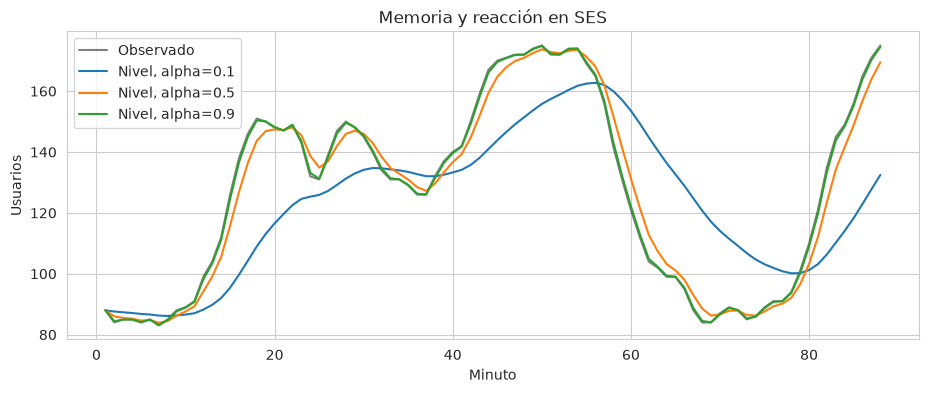

In [25]:
def niveles_ses(y, alpha):
    niveles = [float(y[0])]
    for valor in y:
        niveles.append(alpha * valor + (1-alpha) * niveles[-1])
    return np.asarray(niveles)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train["ds"], y_train, color="black", alpha=0.5, label="Observado")
for alpha in [0.1, 0.5, 0.9]:
    ax.plot(train["ds"], niveles_ses(y_train, alpha)[1:], label=f"Nivel, alpha={alpha}")
ax.set(title="Memoria y reacción en SES", xlabel="Minuto", ylabel="Usuarios")
ax.legend()
plt.show()

### 🔎 Interpreta

Compare suavidad y retraso. ¿Seguir mejor cada dato garantiza menor error futuro?

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Alpha=0.9 reacciona más; alpha=0.1 suaviza más pero responde tarde. Seguir también el ruido puede perjudicar el pronóstico: el ajuste dentro de train no garantiza desempeño en test.

</details>

### 🛠️ Modifica

Agregue alpha=0 y alpha=1; explique los extremos y restaure los valores originales.

## 4. Ajuste automático de SES

`initialization_method="estimated"` estima la inicialización y `.fit(optimized=True)` estima alpha minimizando el error cuadrático de ajuste en train. No elegimos alpha mirando test.

### 🧠 Predice

Si alpha resulta alto, ¿el nivel será lento o reactivo? Ejecute y contraste.

In [26]:
ses = SimpleExpSmoothing(y_train, initialization_method="estimated").fit(optimized=True)
alpha_ses = ses.params["smoothing_level"]
forecast_ses = np.asarray(ses.forecast(h))
print(f"Alpha estimado: {alpha_ses:.4f}; nivel final: {ses.level[-1]:.3f}")
print("Forecast SES:", forecast_ses)

Alpha estimado: 1.0000; nivel final: 175.000
Forecast SES: [174.99999994 174.99999994 174.99999994 174.99999994 174.99999994
 174.99999994 174.99999994 174.99999994 174.99999994 174.99999994
 174.99999994 174.99999994]


<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Un alpha alto implica reacción rápida. No demuestra superioridad frente a naive en test. La trayectoria futura de SES sigue siendo horizontal.

</details>

## 5. Holt: nivel + tendencia

### 📘 Concepto

Holt actualiza $\ell_t$ (nivel, usuarios) y $b_t$ (tendencia local, usuarios por minuto):

$$
\ell_t=\alpha y_t+(1-\alpha)(\ell_{t-1}+b_{t-1})
$$

$$
b_t=\beta^*(\ell_t-\ell_{t-1})+(1-\beta^*)b_{t-1}
$$

$$
\hat{y}_{T+k|T}=\ell_T+k b_T
$$

$\beta^*$ controla la actualización de la pendiente. Nivel alto no implica tendencia positiva.

### 🧠 Predice

¿Cómo diferirá su trayectoria futura respecto a SES?

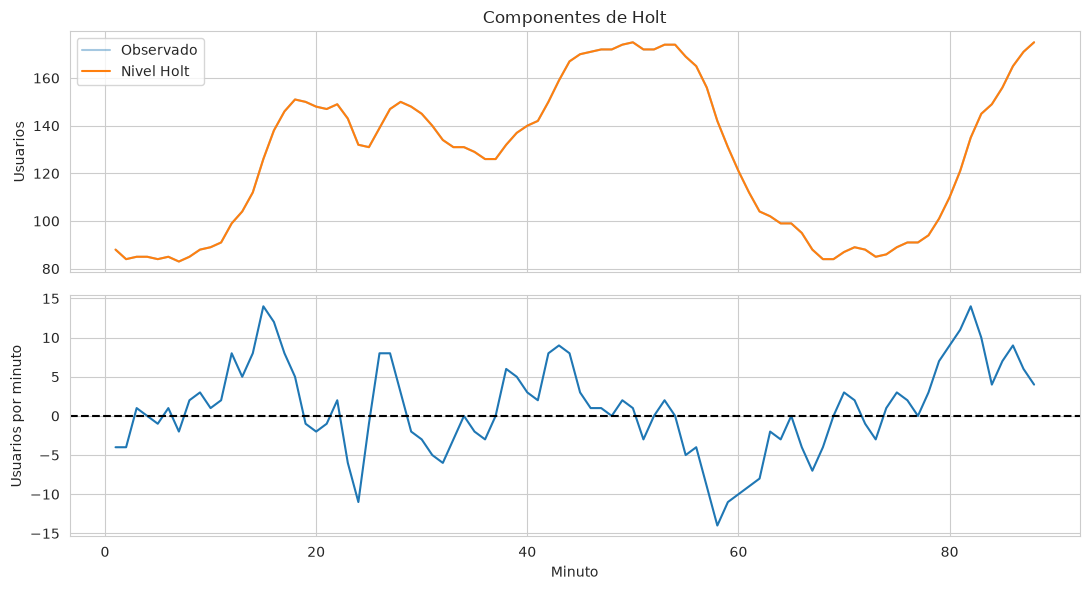

Nivel final: 175.00000002980232 Tendencia final: 4.000000014901163


In [27]:
holt = Holt(y_train, initialization_method="estimated").fit(optimized=True)
forecast_holt = np.asarray(holt.forecast(h))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(train["ds"], y_train, alpha=0.4, label="Observado")
axes[0].plot(train["ds"], holt.level, label="Nivel Holt")
axes[0].set(title="Componentes de Holt", ylabel="Usuarios")
axes[0].legend()
axes[1].plot(train["ds"], holt.trend)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Minuto", ylabel="Usuarios por minuto")
plt.tight_layout()
plt.show()
print("Nivel final:", holt.level[-1], "Tendencia final:", holt.trend[-1])

### 🔎 Interpreta

Localice una pendiente negativa. ¿Implica usuarios negativos? ¿Se prolonga una tendencia global o local?

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Pendiente negativa significa disminución, no nivel negativo. Holt prolonga la tendencia local final; SES conserva un nivel fijo.

</details>

### 🛠️ Modifica

Compare el primer y el último valor de `holt.trend`. Explique por qué una sola recta global puede ser insuficiente.

## 6. Tendencia amortiguada

Una dirección local no tiene por qué mantenerse con igual fuerza indefinidamente. Con $0<\phi<1$:

$$
\hat{y}_{T+k|T}=\ell_T+(\phi+\phi^2+\cdots+\phi^k)b_T
$$

Cuanto más cerca de 1 esté $\phi$, más lenta es la amortiguación. También cambia la actualización de estados; no basta con modificar una recta calculada previamente.

### 🧠 Predice

Con tendencia positiva y estados comparables, ¿qué trayectoria crecerá más a largo plazo: Holt o Holt amortiguado?

Phi estimado: 0.8120456132226893


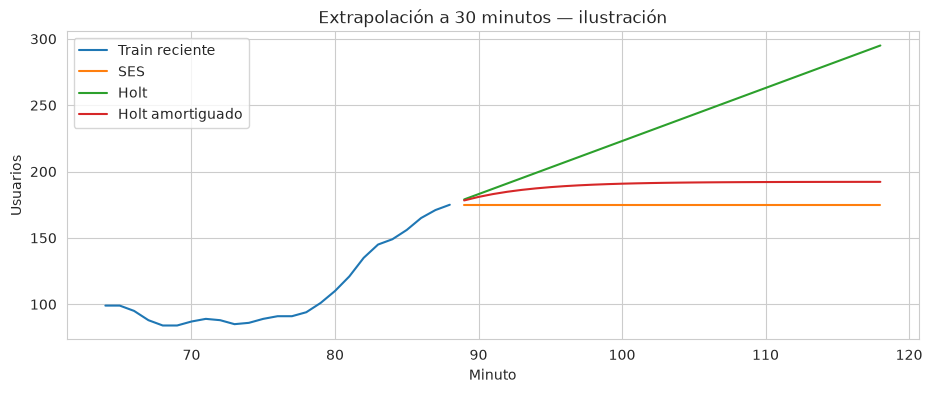

In [28]:
amortiguado = Holt(y_train, damped_trend=True,
                   initialization_method="estimated").fit(optimized=True)
forecast_amortiguado = np.asarray(amortiguado.forecast(h))
print("Phi estimado:", amortiguado.params["damping_trend"])
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train["ds"].tail(25), y_train[-25:], label="Train reciente")
for nombre, modelo in [("SES", ses), ("Holt", holt), ("Holt amortiguado", amortiguado)]:
    ax.plot(np.arange(train["ds"].iloc[-1]+1, train["ds"].iloc[-1]+31),
            modelo.forecast(30), label=nombre)
ax.set(title="Extrapolación a 30 minutos — ilustración", xlabel="Minuto", ylabel="Usuarios")
ax.legend()
plt.show()

### 🔎 Interpreta

¿Por qué podría ser razonable reducir gradualmente el efecto de una tendencia reciente?

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Amortiguar limita la contribución acumulada de tendencia. Cada ajuste puede estimar estados finales distintos: compare las curvas efectivas. La gráfica a 30 minutos ilustra extrapolación; solo hay 12 observaciones reservadas para evaluar.

</details>

### 🛠️ Modifica

Pruebe `.fit(damping_trend=0.9, optimized=True)` en otro Holt amortiguado. Compare con el phi estimado, sin elegirlo por tanteos sobre test. Mantenga el ajuste original en la comparación principal.

## 7. ETS: error, tendencia y estacionalidad

### 📘 Concepto

ETS es una familia de **modelos de espacio de estados**: estados latentes de nivel, tendencia y, cuando corresponde, estacionalidad se actualizan al llegar observaciones. La ecuación de observación relaciona los estados con $Y_t$ y un error aleatorio. Esta formulación permite describir incertidumbre; no exigimos derivar sus ecuaciones completas.

Notación: **ETS(Error, Trend, Seasonal)**.

| Componente | Posibilidades |
|---|---|
| Error | A: aditivo, escala absoluta; M: multiplicativo, escala relativa al nivel. No admite N: siempre hay error. |
| Tendencia | N: ausente; A: aditiva; Ad: aditiva amortiguada. M existe en la taxonomía general, pero no se desarrolla ni habilita aquí. |
| Estacionalidad | N: ausente; A: efecto aditivo; M: efecto proporcional al nivel. |

Los modelos multiplicativos requieren datos estrictamente positivos y condiciones adicionales de admisibilidad.

ETS(A,N,N) corresponde a SES con error aditivo; ETS(A,A,N), a Holt; ETS(A,Ad,N), a tendencia aditiva amortiguada. El tipo de error describe variabilidad, no es otra tendencia.

**Holt-Winters** agrega estacionalidad aditiva o multiplicativa: se menciona para completar la familia, sin convertirse en requisito. Una serie semanal no exige automáticamente un período de 52 semanas.

## 8. Uso práctico de AutoETS

### 💻 Entendamos el código

`AutoETS(season_length=1, model="ZZN")` busca estructuras no estacionales. Las dos `Z` indican que AutoETS puede seleccionar automáticamente entre las alternativas admisibles para el tipo de error y la tendencia, mientras que `N` fija ausencia de componente estacional.

Por tanto, `ZZN` no es el modelo ETS final. Después del ajuste, AutoETS reporta la estructura seleccionada con una notación como `ETS(A,N,N)` o `ETS(A,Ad,N)`. La selección se realiza con AICc usando únicamente `train`; luego el modelo debe evaluarse fuera de muestra sobre `test`.

AICc no es un error en test; aquí no se compara entre librerías. La estructura seleccionada se interpreta y se evalúa externamente.

### 🧠 Predice

¿Debe seleccionar tendencia? ¿Un AICc menor garantiza menor MAE futuro?

In [29]:
auto = AutoETS(season_length=1, model="ZZN").fit(y_train)
forecast_auto = auto.predict(h=h)["mean"]
modelo_ets = auto.model_["method"]
print("Modelo seleccionado:", modelo_ets)
print("AICc (train):", auto.model_["aicc"])

Modelo seleccionado: ETS(A,Ad,N)
AICc (train): 671.0596076177744


### 🔎 Interpreta

Decodifique error, tendencia y estacionalidad del nombre impreso. Si aparece Ad, explique qué ocurre con la pendiente al aumentar el horizonte.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Para esta partición se obtiene ETS(A,Ad,N): error aditivo, tendencia aditiva amortiguada y ninguna estacionalidad. No era obligatorio seleccionar tendencia; AICc decide entre candidatos con train y no garantiza menor MAE en test.

</details>

### 🛠️ Modifica

Compare con `AutoETS(season_length=1, model="ANN")`. ¿Qué decisiones dejó de tomar automáticamente? Restaure ZZN.

## 9. Pronósticos sobre el mismo test

Incluimos los tres benchmarks de Semana 2. Fijamos **naive como referencia principal de persistencia antes de comparar ETS** y reportamos mean y drift para no omitir referencias competitivas. En el proyecto se conserva el benchmark del Hito 2, que puede ser distinto.

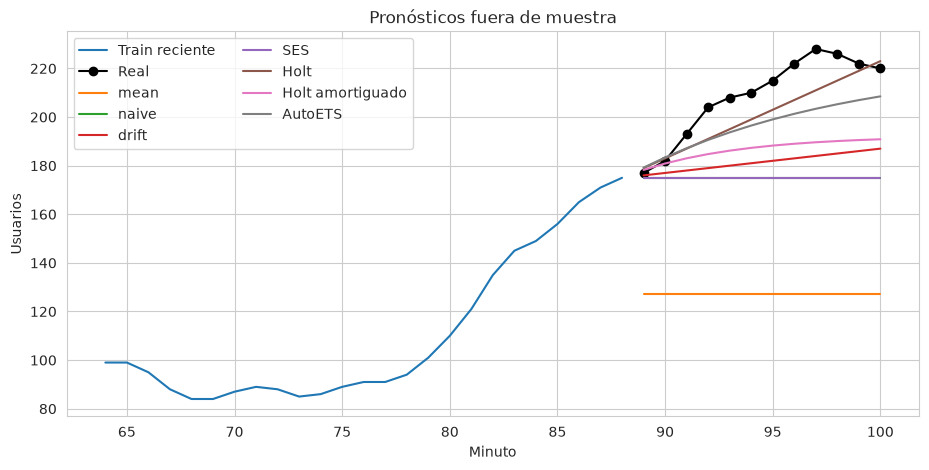

,ds,real,mean,naive,drift,SES,Holt,Holt amortiguado,AutoETS
0,89,177.0,127.284091,175.0,176.0,175.0,179.0,178.248182,179.190402
1,90,182.0,127.284091,175.0,177.0,175.0,183.0,180.885855,183.380725
2,91,193.0,127.284091,175.0,178.0,175.0,187.0,183.027765,187.170382
3,92,204.0,127.284091,175.0,179.0,175.0,191.0,184.767094,190.597682
4,93,208.0,127.284091,175.0,180.0,175.0,195.0,186.179508,193.697274
5,94,210.0,127.284091,175.0,181.0,175.0,199.0,187.326453,196.500491
6,95,215.0,127.284091,175.0,182.0,175.0,203.0,188.257825,199.035673
7,96,222.0,127.284091,175.0,183.0,175.0,207.0,189.014141,201.328448
8,97,228.0,127.284091,175.0,184.0,175.0,211.0,189.628304,203.401994
9,98,226.0,127.284091,175.0,185.0,175.0,215.0,190.127033,205.277274


In [30]:
pronosticos = {
    "mean": np.repeat(y_train.mean(), h),
    "naive": np.repeat(y_train[-1], h),
    "drift": y_train[-1]+np.arange(1,h+1)*(y_train[-1]-y_train[0])/(len(y_train)-1),
    "SES": forecast_ses, "Holt": forecast_holt,
    "Holt amortiguado": forecast_amortiguado, "AutoETS": forecast_auto,
}
comparacion = pd.DataFrame({"ds": test["ds"].to_numpy(), "real": y_test, **pronosticos})
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(train["ds"].tail(25), y_train[-25:], label="Train reciente")
ax.plot(test["ds"], y_test, marker="o", color="black", label="Real")
for nombre, valores in pronosticos.items():
    ax.plot(test["ds"], valores, label=nombre)
ax.set(title="Pronósticos fuera de muestra", xlabel="Minuto", ylabel="Usuarios")
ax.legend(ncol=2)
plt.show()
comparacion

## 10. MAE, RMSE y MASE

Para $e_t=y_t-\hat{y}_t$, sobre las mismas $h$ observaciones de test:

$$
MAE=\frac{1}{h}\sum_{t=T+1}^{T+h}|e_t|,\qquad
RMSE=\sqrt{\frac{1}{h}\sum_{t=T+1}^{T+h}e_t^2}
$$

$$
MASE=\frac{MAE}{\frac{1}{T-1}\sum_{t=2}^{T}|y_t-y_{t-1}|}
$$

MAE y RMSE están en usuarios; RMSE penaliza más errores grandes. MASE no tiene unidades y su escala usa exclusivamente train. Si es prácticamente cero, reportamos `np.nan`.

**MASE menor que 1** significa menor MAE que la escala naive de un paso dentro de train. No demuestra superar al naive de horizonte $h$ sobre test: hay que comparar sus métricas en ese mismo test.

In [31]:
def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true)-np.asarray(y_pred)))

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.asarray(y_true)-np.asarray(y_pred))**2))

def mase(y_train, y_true, y_pred):
    escala = np.mean(np.abs(np.diff(np.asarray(y_train))))
    if np.isclose(escala, 0):
        return np.nan
    return mae(y_true, y_pred)/escala

metricas = pd.DataFrame([
    {"metodo": nombre, "MAE": mae(y_test, pred), "RMSE": rmse(y_test, pred),
     "MASE": mase(y_train, y_test, pred)} for nombre, pred in pronosticos.items()
]).set_index("metodo").sort_values("MAE")
metricas

,MAE,RMSE,MASE
metodo,,,
Holt,8.916667,10.396313,2.004522
AutoETS,13.256801,14.949005,2.980211
Holt amortiguado,22.553441,25.599743,5.070153
drift,27.416667,30.431617,6.163437
naive,33.916667,37.622024,7.624677
SES,33.916667,37.622024,7.624677
mean,81.632576,83.240338,18.351509


### 🧠 Predice → ▶ Ejecuta → 🔎 Interpreta

Anticipe el ranking mirando las trayectorias y ejecute la tabla. ¿Coinciden MAE y RMSE? ¿El mejor suavizamiento supera naive y también los otros benchmarks?

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Compare las filas calculadas sin suponer que complejidad implica mejora. Cambios de ranking con RMSE reflejan el peso de errores grandes. Con la misma escala de train, el ranking MASE coincide con MAE.

</details>

## 11. Residuos: ¿queda estructura sin explicar?

El residuo de un paso es observado menos predicción de un paso en train. Se diferencia del error de test: este último procede de pronósticos a varios pasos desde un origen fijo.

`predict_in_sample()["fitted"]` entrega ajustes de AutoETS; calculamos residuos en unidades originales, incluso si se eligiera error multiplicativo. Revisamos gráfico temporal, media y ACF. Una media próxima a cero no implica ausencia de dependencia. Las bandas de ACF son aproximadas: algún pico aislado puede ocurrir por azar. La ACF detecta dependencia lineal, sin certificar independencia ni buen desempeño futuro.

Media de residuos (usuarios): 0.5418


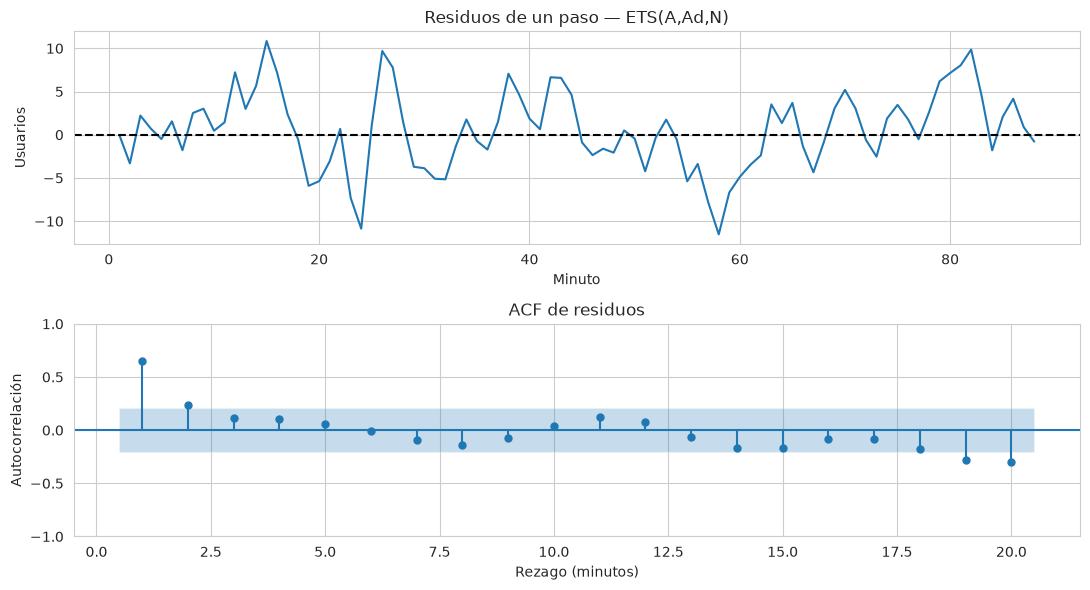

In [32]:
ajustados = auto.predict_in_sample()["fitted"]
residuos = y_train-ajustados
media_residuos = np.mean(residuos)
acf_residuos = acf(residuos, nlags=20)
print(f"Media de residuos (usuarios): {media_residuos:.4f}")
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(train["ds"], residuos)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(title=f"Residuos de un paso — {modelo_ets}", xlabel="Minuto", ylabel="Usuarios")
plot_acf(residuos, lags=20, zero=False, bartlett_confint=False, ax=axes[1])
axes[1].set(title="ACF de residuos", xlabel="Rezago (minutos)", ylabel="Autocorrelación")
plt.tight_layout()
plt.show()

### 🔎 Interpreta

¿La media es pequeña respecto al nivel? ¿Hay rachas, variabilidad cambiante o autocorrelaciones sistemáticas? Conecte con la persistencia de Semana 1.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

La media mide sesgo promedio en train, pero errores positivos y negativos pueden compensarse. Autocorrelaciones sistemáticas sugieren estructura lineal pendiente. Un modelo puede mejorar el benchmark y todavía dejar dependencia residual.

</details>

### 🛠️ Modifica

Repita el diagnóstico con `y_train-ses.fittedvalues` y `y_train-holt.fittedvalues`. Compare con AutoETS. Después cambie el horizonte a 8 y ejecute todo desde la partición; no reutilice modelos de otro corte. Restaure 12.

## 12. Decisión: ¿mejora realmente al benchmark?

La reducción porcentual de MAE frente a naive es positiva si hay mejora. Si su MAE es cero, la reducción relativa no se define.

In [33]:
mae_base = metricas.loc["naive", "MAE"]
mejora = (100*(1-metricas["MAE"]/mae_base) if not np.isclose(mae_base,0)
          else metricas["MAE"]*np.nan)
print("Reducción de MAE frente a naive (%):")
print(mejora.round(2))

Reducción de MAE frente a naive (%):
metodo
Holt                 73.71
AutoETS              60.91
Holt amortiguado     33.50
drift                19.16
naive                 0.00
SES                  -0.00
mean               -140.69
Name: MAE, dtype: float64


### 🔎 Respuesta razonada y decisión

En máximo 150 palabras indique qué suavizamiento funcionó mejor, si supera al benchmark, qué capturó y qué dejó en residuos. Cite horizonte, partición y las tres métricas. Diferencias pequeñas en un solo test no prueban superioridad universal; reutilizar test para muchas decisiones vuelve optimista la comparación.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

La decisión integra métricas fuera de muestra, estructura de la serie y diagnóstico residual. Si ETS no mejora, conservar el benchmark es válido. Si mejora pero quedan autocorrelaciones, hay progreso y estructura pendiente. La selección definitiva del proyecto sigue abierta.

</details>

## 13. Hito 3 y siguiente semana

Recuperen benchmark y partición del Hito 2; ajusten SES, Holt, una variante amortiguada y AutoETS; interpreten su estructura, comparen métricas y revisen residuos, media y ACF. Conecten con Hito 1.

$X_t$ sigue siendo el estado del sistema; estos métodos pronostican $Y_t$ sin usar automáticamente el estado como predictor. Los cuatro casos tienen 208 semanas: `vibracion_rms`, `porcentaje_no_conformes`, `solicitudes` o `usuarios_activos`. No fuerce estacionalidad; Servicios puede requerir mayor atención a tendencia.

Semana 4 retomará dependencia pendiente, estacionariedad y diferenciación. Cerramos una comparación provisional.

## 14. Referencia y cierre

[FPP3, capítulo 8 — Exponential smoothing](https://otexts.com/fpp3/exponential-smoothing.html): §8.1 SES; §8.2 tendencia y amortiguación; §8.3 solo como contexto; §8.5–8.7 ETS, selección y pronóstico.

> Ajustar mejor el pasado no basta: la flexibilidad debe aportar valor fuera de muestra y tener una interpretación coherente con el sistema.